# 03 · 为新物体找到一份形状配方

上一篇练好了一台共享的“形状机器”。现在来了一个新椭球：我们拿到一些空间点及其距离读数，想找到一份 z，让机器画出的形状符合这些观测。

这次**机器固定，只调配方**。你会看到随机编码对应的形状，怎样在观测反馈下逐步靠近目标。

## 准备好上一篇的模型

先在[多物体 Auto-Decoder](02_多物体Auto-Decoder.ipynb)中完成训练并保存 `artifacts/auto_decoder.pt`，再使用 `deepsdf` 环境从本篇第一格运行。各变量在这里重新初始化，模型通过文件传过来。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path

# 固定随机种子，便于复现实验
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# 自动选择设备
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

# 绘图默认参数
plt.rcParams["figure.figsize"] = (6, 5)
plt.rcParams["axes.grid"] = True

PyTorch: 2.14.1
Device: cpu


## 1. 把训练好的解码器装回来

检查点保存了网络结构尺寸和各层权重。先按这些尺寸搭出 MLP，再用 `load_state_dict` 把学到的参数放回去。

这里读取自己生成的 `artifacts/auto_decoder.pt`，使用 `weights_only=True` 加载其中的张量与基础类型。外部权重文件应来自可信来源。

In [2]:
checkpoint_path = Path("artifacts/auto_decoder.pt")
if not checkpoint_path.is_file():
    raise FileNotFoundError(
        "未找到 artifacts/auto_decoder.pt，请先运行第二篇的训练和保存单元。"
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)
latent_dim = checkpoint["latent_dim"]
hidden_dim = checkpoint["hidden_dim"]
lambda_latent = checkpoint["lambda_latent"]
train_radii = checkpoint["train_radii"]

decoder = nn.Sequential(
    nn.Linear(latent_dim + 3, hidden_dim),
    nn.ReLU(),
    nn.Linear(hidden_dim, hidden_dim),
    nn.ReLU(),
    nn.Linear(hidden_dim, hidden_dim),
    nn.ReLU(),
    nn.Linear(hidden_dim, 1),
).to(device)
decoder.load_state_dict(checkpoint["decoder_state_dict"])
decoder.eval()
print("Loaded:", checkpoint_path.resolve())
print("Training shapes:", len(train_radii))

Loaded: /Users/scy/Repo/experiments/learnx-from0/deepsdf/artifacts/auto_decoder.pt
Training shapes: 8


## 2. 准备新形状的距离读数

沿用上一篇的椭球近似距离函数：先把坐标按半轴缩放，求它离单位球面的带符号偏移，再乘最小半轴。

这样可以给新椭球周围的点快速生成标签：表面读零，内部读负，外部读正。下面先定义函数，再挑出靠近表面的观测。

In [3]:
def ellipsoid_sdf_approx(points, radii):
    """
    椭球体的近似 SDF。

    points: (N, 3)
    radii:  (3,)，分别是 x/y/z 方向的半轴长度。

    该公式保证零等值面符合目标椭球，
    但在一般位置上并非精确的欧氏距离。
    """
    radii = torch.as_tensor(
        radii,
        dtype=points.dtype,
        device=points.device,
    )

    normalized_radius = torch.linalg.norm(
        points / radii,
        dim=-1,
        keepdim=True,
    )

    return (normalized_radius - 1.0) * radii.min()

## 2.1 在新椭球周围，收集一圈“测距便签”

目标椭球的半轴是 `[0.58,0.48,0.68]`。在空间里先撒 10 万个候选点，保留近似 SDF 绝对值小于 0.12 的点，再随机选出最多 1500 个。

每张便签上写着两件事：**我在哪个坐标，这里的距离读数是多少。** 它们分布在整个椭球表面附近，接下来用来约束同一份新编码 z。

In [4]:
# 这个形状没有出现在 train_radii 中
target_radii = torch.tensor(
    [0.58, 0.48, 0.68],
    dtype=torch.float32,
)

# 在空间中随机采样大量点
candidate_points = torch.rand(100_000, 3) * 2 - 1

candidate_sdf = ellipsoid_sdf_approx(
    candidate_points, target_radii
)

# 从整个表面附近随机抽取带距离标签的观测点
# candidate_sdf 的形状是 (N, 1)，所以掩码需要先压成 (N,)
# 才能用来索引 (N, 3) 的坐标张量
surface_mask = (candidate_sdf.abs() < 0.12).squeeze(-1)

observed_points = candidate_points[surface_mask]
observed_sdf = candidate_sdf[surface_mask]

# 随机选择一部分观测
num_observations = min(1500, len(observed_points))

selection = torch.randperm(len(observed_points))[
    :num_observations
]

observed_points = observed_points[selection].to(device)
observed_sdf = observed_sdf[selection].to(device)

print("Observation points:", observed_points.shape)

Observation points: torch.Size([1500, 3])


得到的 `observed_points` 和 `observed_sdf` 是一一对应的观测。拟合时，网络只接收这些坐标和标签；目标半轴留给我们生成数据和画对照图。

以后换成接触或深度观测时，损失也要跟着数据形式改变：坐标、法向、深度分别提供不同的几何约束。

## 3. 固定机器，只转动配方上的旋钮

先冻结解码器权重，再初始化一条新的 `test_latent`。把同一个编码复制给所有观测点，拼上各自坐标，让网络给出预测距离。

损失仍由距离 L1 和编码正则项组成，但优化器这次只接收 `[test_latent]`。下面更新 1500 步，最初的编码也会另存一份，供后面画“开始前”的截面。

这里有个关键动作：**冻结参数，同时保留经过解码器的梯度路径。** 像测量一台固定机器对输入旋钮的响应，机器的权重保持不变，梯度仍能告诉我们怎样转动 z。

In [5]:
decoder.eval()

# 冻结解码器参数
for parameter in decoder.parameters():
    parameter.requires_grad_(False)

# 初始化新的潜在编码
test_latent = nn.Parameter(
    torch.randn(1, latent_dim, device=device) * 0.01
)

initial_latent = test_latent.detach().clone()

latent_optimizer = torch.optim.Adam(
    [test_latent],
    lr=1e-2,
)

latent_loss_history = []

for step in range(1500):
    # 将同一个潜在编码复制到所有观测点
    latent_batch = test_latent.expand(
        len(observed_points), -1
    )

    decoder_input = torch.cat(
        [latent_batch, observed_points], dim=-1
    )

    predicted_sdf = decoder(decoder_input)

    # 只拟合当前物体的观测
    data_loss = F.l1_loss(
        predicted_sdf, observed_sdf
    )

    # 潜在编码正则化
    latent_reg = test_latent.pow(2).sum()

    loss = data_loss + lambda_latent * latent_reg

    latent_optimizer.zero_grad()
    loss.backward()
    latent_optimizer.step()

    latent_loss_history.append(loss.item())

    if (step + 1) % 300 == 0:
        print(
            f"Step {step + 1:4d}/1500, "
            f"Loss={loss.item():.6f}"
        )

Step  300/1500, Loss=0.003806
Step  600/1500, Loss=0.004063
Step  900/1500, Loss=0.003480
Step 1200/1500, Loss=0.003658
Step 1500/1500, Loss=0.003642


看优化器里只有一个对象：`test_latent`。每次更新都在调整这份新配方；同一份解码器会根据新的 z，为所有观测坐标重新给出距离。

## 4. 同一台机器，换配方前后画出了什么？

把三个 z=0 截面并排：目标形状、初始编码、优化后的编码。三张图使用相同颜色范围，黑线都表示零等值线。

先看黑线的位置与长短轴，再看线内外的颜色变化。这样可以同时观察轮廓怎样移动、周围的距离预测怎样调整。

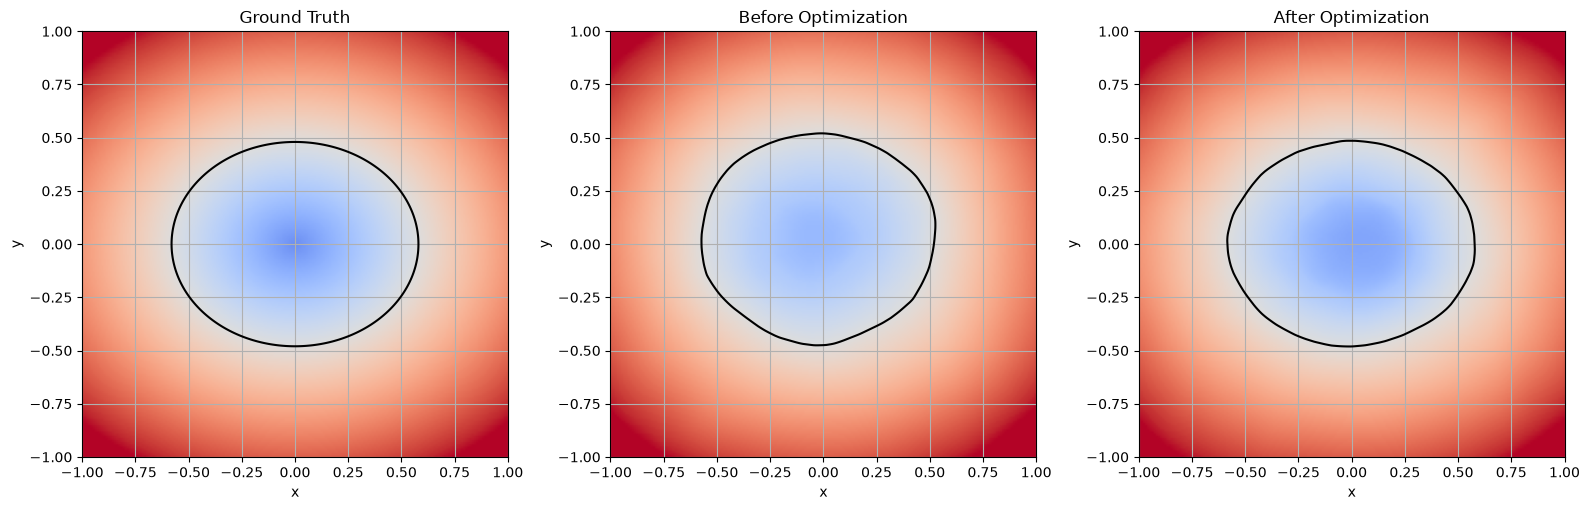

In [6]:
resolution = 200

axis = torch.linspace(-1, 1, resolution)
X, Y = torch.meshgrid(axis, axis, indexing="xy")
Z = torch.zeros_like(X)

query_xyz = torch.stack(
    [X.flatten(), Y.flatten(), Z.flatten()],
    dim=-1,
).to(device)

with torch.no_grad():
    # 重建前：使用优化开始时保存的初始潜在编码
    initial_input = torch.cat(
        [
            initial_latent.expand(len(query_xyz), -1),
            query_xyz,
        ],
        dim=-1,
    )

    initial_sdf = decoder(
        initial_input
    ).cpu().numpy().reshape(resolution, resolution)

    # 重建后：使用优化得到的潜在编码
    fitted_input = torch.cat(
        [
            test_latent.expand(len(query_xyz), -1),
            query_xyz,
        ],
        dim=-1,
    )

    fitted_sdf = decoder(
        fitted_input
    ).cpu().numpy().reshape(resolution, resolution)

# 真实目标的截面
true_sdf = ellipsoid_sdf_approx(
    query_xyz.cpu(), target_radii
).numpy().reshape(resolution, resolution)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, values, title in zip(
    axes,
    [true_sdf, initial_sdf, fitted_sdf],
    ["Ground Truth", "Before Optimization", "After Optimization"],
):
    ax.imshow(
        values,
        extent=[-1, 1, -1, 1],
        origin="lower",
        cmap="coolwarm",
        vmin=-0.7,
        vmax=0.7,
    )
    ax.contour(
        X.numpy(), Y.numpy(), values,
        levels=[0], colors="black",
    )
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

比较初始与优化后的黑线，找出变化最大的方向，再看它与目标轮廓还有多大间距。一次修改一个设置，比如观测数量、迭代步数或正则化权重，会更容易看清它各自带来的影响。

新编码能表达的形状，来自它与共享解码器的共同作用；训练形状提供了这台机器学到的形状经验。

## 把三篇连成一条线

第一篇学会查询一个球的距离；第二篇给多个物体分配编码，共同训练解码器；第三篇固定解码器，为新物体拟合编码。

<details>
<summary>为什么一个函数能表示三维表面？</summary>

它在每个坐标返回带符号距离。所有零读数位置组成物体表面；查询足够多的位置后，可以提取出三角网格。

</details>

<details>
<summary>共享解码器怎样区分不同物体？</summary>

坐标旁边还带着潜在编码 z。它提供物体特定的信息，网络共同使用 z 和坐标来预测距离。

</details>

<details>
<summary>训练物体与新物体的优化，改动了什么？</summary>

训练阶段同时调整 θ 和各物体的 z；新物体拟合阶段保持 θ 固定，优化一条新的 z。

</details>

<details>
<summary>冻结解码器后，梯度怎样到达 z？</summary>

解码器仍在执行可微计算，只是权重不参与更新。损失沿这些计算对输入 z 求导，优化器再更新 z；因此编码拟合的前向需要保留自动微分记录。

</details>

继续阅读 [DeepSDF 论文](https://arxiv.org/abs/1901.05103)与[官方实现](https://github.com/facebookresearch/DeepSDF)时，可以带着三个问题去看：表面附近怎样采样，截断 L1 怎样使用，潜在编码的先验怎样影响形状。